step 1: simulate + save
response patterns: {'good': 79, 'slow': 54, 'non': 37, 'deteriorating': 30}
baseline severity: {'moderate': 67, 'severe': 62, 'extreme': 47, 'mild': 24}
rows: 16800 sensing, 33600 tasks, 2600 caps visits
locf vs truth: {'MAE': 3.41, 'RMSE': 4.36, 'pearson_r': 0.957, 'severity_accuracy': 0.774}


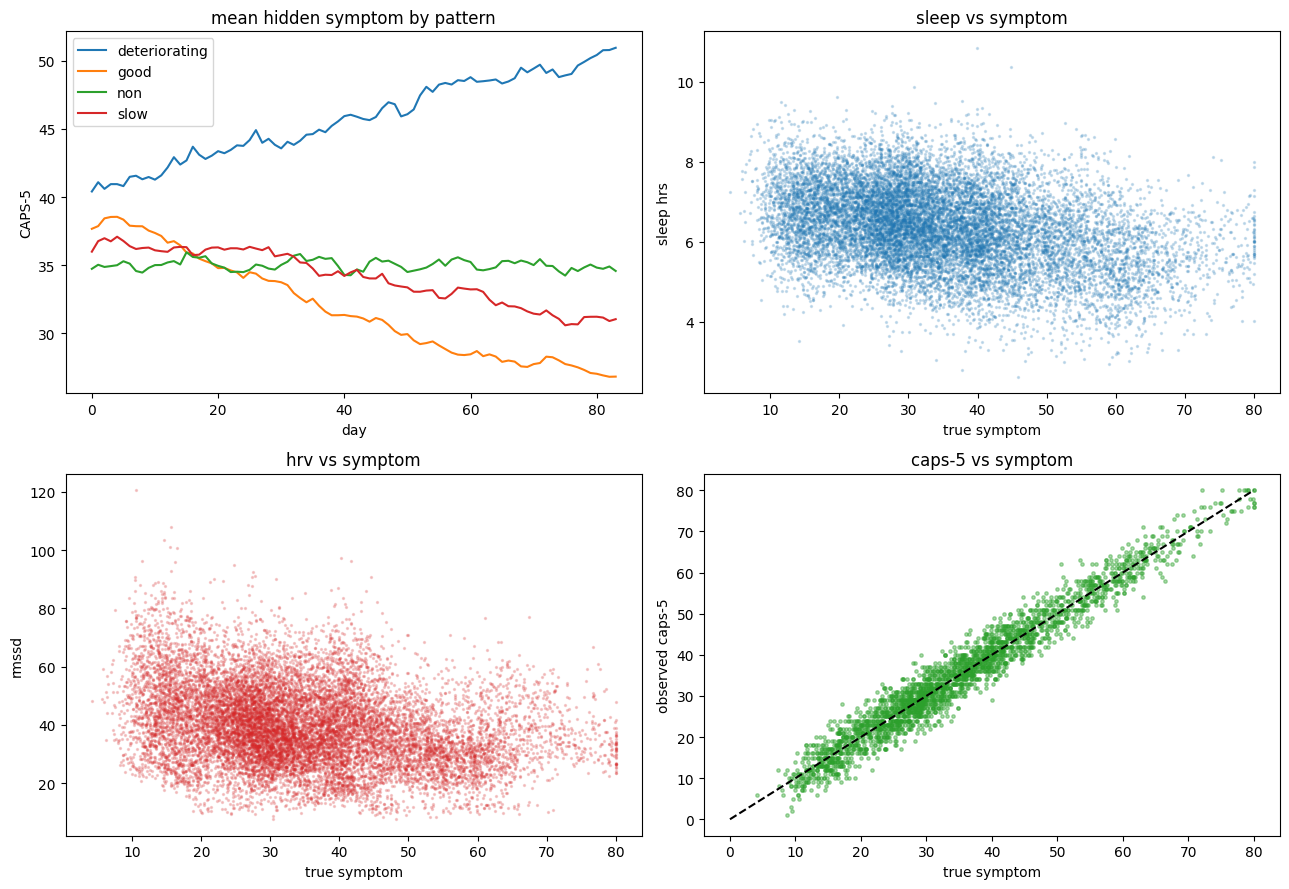

saved sim_output.zip

step 2: configure agents
default: {'feasible': False, 'violations': ['crisis recall 0.38 < 0.75'], 'fitness': 0.445, 'mean_improvement': 0.136, 'privacy': 0.816, 'fairness': 0.396, 'crisis_recall': 0.375}
  decade  1 | best  -0.368 | empires 3 | tried  36 | feasible   5
  decade  2 | best  -0.379 | empires 2 | tried  53 | feasible  10
  decade  3 | best  -0.387 | empires 2 | tried  71 | feasible  23
  decade  4 | best  -0.387 | empires 2 | tried  88 | feasible  35
  decade  5 | best  -0.395 | empires 2 | tried 106 | feasible  47
  decade  6 | best  -0.398 | empires 2 | tried 124 | feasible  56
  decade  7 | best  -0.398 | empires 2 | tried 141 | feasible  64
  decade  8 | best  -0.416 | empires 2 | tried 158 | feasible  75
  decade  9 | best  -0.424 | empires 2 | tried 176 | feasible  84
  decade 10 | best  -0.424 | empires 2 | tried 194 | feasible  91
  decade 11 | best  -0.424 | empires 2 | tried 212 | feasible 100
  decade 12 | best  -0.424 | empires 2 | tried 

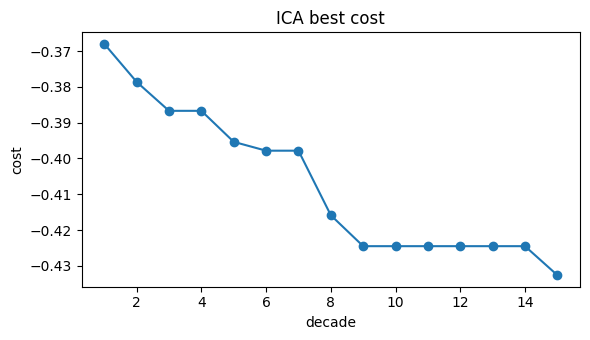

saved agent_config.json, found by ICA

step 3: run saved agents on new patients
{
  "access": {
    "safety": [
      "caps",
      "task_history"
    ],
    "cbt": [
      "demographics",
      "caps",
      "wearable",
      "phone"
    ],
    "journaling_coach": [],
    "reflection_coach": [
      "caps"
    ],
    "breathing_coach": []
  },
  "retention": 7,
  "alert_threshold": 4,
  "sensor_weight": 0,
  "max_load": 2,
  "exposure_start_week": 2,
  "clinician_review": true,
  "stabilise_on_alert": false
}
feasible                                                                     True
violations                                                                     []
fitness                                                                  0.504049
quality                                                                  0.561221
mean_improvement                                                         0.159182
cbt_fidelity                                                             0

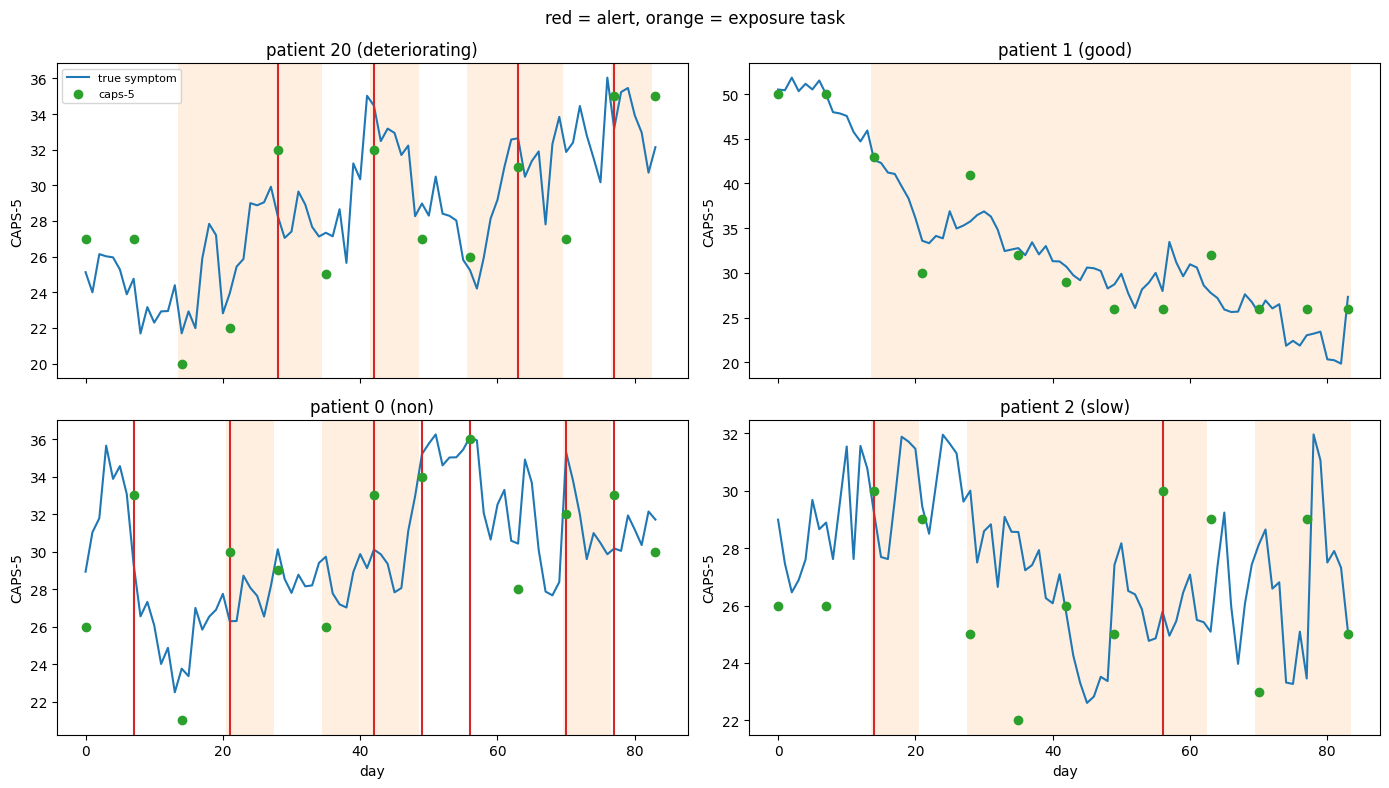


saved agent_run.zip, total 9.0 min
(simulation only, not clinical evidence)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ptsd multi-agent sim
# step 1: simulate patients on fixed protocol -> sim_output.zip
# step 2: set up agents (default config, optionally tuned w/ ICA) -> agent_config.json
# step 3: run saved agents on a new cohort -> agent_run.zip
# NOTE: all simulated, the relationships are my assumptions. needs clinician review

import os, json, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USE_ICA = True       # False = just use default config, way faster
SIM_SEED = 2026
TRAIN_SEED = 2026
TRAIN_N = 80
TEST_SEED = 7
TEST_N = 200
N_DECADES = 15
N_COUNTRIES = 20
DOWNLOAD = True


# ---- simulator ----

N_PATIENTS, N_DAYS, CAPS_MAX, MAX_TASKS = 200, 84, 80, 3
CAPS_DAYS = set(range(0, N_DAYS, 7)) | {N_DAYS - 1}   # weekly + last day

SEVERITY_BANDS = {"mild": (11, 22), "moderate": (23, 34), "severe": (35, 46), "extreme": (47, 70)}
SEVERITY_P = {"mild": 0.15, "moderate": 0.35, "severe": 0.35, "extreme": 0.15}

# hidden response types
RESPONSE = {
    "good":          dict(p=0.40, max_drop=0.55, rate=1.0, lag=0,  worsen=0.00),
    "slow":          dict(p=0.30, max_drop=0.45, rate=0.6, lag=28, worsen=0.00),
    "non":           dict(p=0.20, max_drop=0.08, rate=0.3, lag=0,  worsen=0.00),
    "deteriorating": dict(p=0.10, max_drop=0.10, rate=0.3, lag=0,  worsen=0.30),
}
DOSE_HALF = 40.0

# fit = symptom range (fraction of 80) where the task works best
TASKS = {
    "psychoeducation":         dict(difficulty=0.10, benefit=0.3, fit=(0.00, 1.00)),
    "mood_trigger_log":        dict(difficulty=0.20, benefit=0.4, fit=(0.00, 1.00)),
    "breathing_grounding":     dict(difficulty=0.15, benefit=0.5, fit=(0.45, 1.00)),
    "sleep_hygiene":           dict(difficulty=0.25, benefit=0.5, fit=(0.30, 1.00)),
    "behavioral_activation":   dict(difficulty=0.40, benefit=0.7, fit=(0.20, 0.70)),
    "cognitive_restructuring": dict(difficulty=0.55, benefit=0.9, fit=(0.20, 0.65)),
    "in_vivo_exposure":        dict(difficulty=0.70, benefit=1.2, fit=(0.15, 0.55)),
    "imaginal_exposure":       dict(difficulty=0.80, benefit=1.3, fit=(0.15, 0.50)),
}
OFF_FIT = 0.3

SENSORS = ["sleep_hours", "sleep_efficiency", "night_awakenings", "hrv_rmssd_ms", "resting_hr_bpm",
           "steps", "time_at_home_pct", "unique_locations", "calls_texts", "night_screen_min"]
WEARABLE, PHONE = SENSORS[:5], SENSORS[5:]


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def caps_category(score):
    if score <= 10: return "minimal"
    if score <= 22: return "mild"
    if score <= 34: return "moderate"
    if score <= 46: return "severe"
    return "extreme"

def _py(v):
    return v.item() if hasattr(v, "item") else v


def make_patients(rng, n):
    obs, hid = [], []
    for pid in range(n):
        sex = rng.choice(["male", "female"], p=[0.78, 0.22])
        age = int(np.clip(rng.normal(36, 9), 20, 65))
        deployments = int(min(rng.poisson(1.6), 6))
        trauma_p = [0.55, 0.25, 0.12, 0.08] if sex == "female" else [0.75, 0.03, 0.12, 0.10]
        tbi = bool(rng.random() < 0.15 + 0.05 * deployments)
        depression = bool(rng.random() < 0.45)
        substance = bool(rng.random() < 0.20)

        band = rng.choice(list(SEVERITY_P), p=list(SEVERITY_P.values()))
        lo, hi = SEVERITY_BANDS[band]
        true_baseline = float(np.clip(rng.uniform(lo, hi) + 2 * depression, 11, 75))
        response = str(rng.choice(list(RESPONSE), p=[r["p"] for r in RESPONSE.values()]))
        rater_bias = rng.normal(0, 1.5)
        baseline_caps = int(np.clip(round(true_baseline + rater_bias + 3 * rng.normal()), 0, CAPS_MAX))
        sev = caps_category(baseline_caps)
        if sev == "minimal":
            sev = "mild"

        obs.append(dict(
            patient_id=pid, age=age, sex=sex,
            ethnicity=rng.choice(["White", "Black", "Hispanic/Latino", "Asian", "Other/Multiple"],
                                 p=[0.55, 0.18, 0.17, 0.04, 0.06]),
            branch=rng.choice(["Army", "Navy", "Air Force", "Marine Corps"], p=[0.45, 0.20, 0.15, 0.20]),
            service_status=rng.choice(["active_duty", "reserve_guard", "veteran"], p=[0.35, 0.20, 0.45]),
            rank=rng.choice(["junior_enlisted", "senior_enlisted", "officer"], p=[0.35, 0.45, 0.20]),
            years_service=int(np.clip(rng.normal(9, 5), 1, 30)),
            n_deployments=deployments,
            combat_exposure=0.0 if deployments == 0 else round(float(np.clip(rng.beta(2, 2) + 0.1 * deployments, 0, 1)), 2),
            index_trauma=rng.choice(["combat", "military_sexual_trauma", "training_accident", "other"], p=trauma_p),
            tbi_history=tbi, comorbid_depression=depression, substance_use=substance,
            baseline_caps5=baseline_caps, baseline_severity=sev,
        ))
        # agents never see this part
        hid.append(dict(
            patient_id=pid, true_baseline=round(true_baseline, 2), true_baseline_band=band,
            response_pattern=response,
            motivation=rng.normal(0, 1) - 0.4 * depression - 0.3 * substance,
            rater_bias=rater_bias, baseline_caps_obs=baseline_caps,
            sensitivity=float(rng.lognormal(0, 0.3)),
            sleep_base=rng.normal(7.2, 0.6) - 0.3 * tbi,
            rmssd_base=max(15.0, rng.normal(48 - 0.4 * (age - 36), 12)),
            hr_base=rng.normal(64, 6),
            steps_base=max(2000.0, rng.normal(8000 - 60 * (age - 36), 2000)),
            home_base=float(np.clip(rng.normal(0.60, 0.10), 0.30, 0.85)),
            loc_base=max(1.5, rng.normal(4, 1.2)),
            social_base=max(2.0, rng.normal(12, 5)),
            screen_base=max(0.0, rng.normal(40, 20)),
            wear_miss=rng.beta(1.5, 15), phone_miss=rng.beta(1, 25),
        ))
    return pd.DataFrame(obs), pd.DataFrame(hid)


class PatientView:
    # only observed data goes in here
    def __init__(self, profile):
        self.profile = {k: _py(v) for k, v in profile.items()}
        self.day = 0
        self.caps, self.tasks, self.sensing = [], [], []

    def last_caps(self):
        return self.caps[-1]["caps5_total"] if self.caps else None

    def completion_rate(self, days=7, default=None):
        recent = [r["completed"] for r in self.tasks if self.day - days <= r["day"] < self.day]
        return round(float(np.mean(recent)), 3) if recent else default


class PTSDSimulator:
    def __init__(self, seed=2026, n_patients=N_PATIENTS, n_days=N_DAYS):
        self.n, self.n_days = n_patients, n_days
        pop_ss, *pat_ss = np.random.SeedSequence(seed).spawn(n_patients + 1)
        self.patients, self.patients_hidden = make_patients(np.random.default_rng(pop_ss), n_patients)
        self._hidden = self.patients_hidden.to_dict("records")

        # draw noise up front so every policy gets the same luck
        self._noise = []
        for s in pat_ss:
            r = np.random.default_rng(s)
            self._noise.append(dict(
                eps=r.normal(size=n_days), shock_u=r.random(n_days), shock_mag=r.uniform(4, 10, n_days),
                task_u=r.random((n_days, MAX_TASKS)), sensor=r.normal(size=(n_days, len(SENSORS))),
                miss=r.random((n_days, 2)), caps=r.normal(size=n_days)))

    def run(self, policy):
        hid_rows, sens_rows, task_rows, caps_rows = [], [], [], []
        for pid in range(self.n):
            hp = self._hidden[pid]
            nz = self._noise[pid]
            resp = RESPONSE[hp["response_pattern"]]
            view = PatientView(self.patients.iloc[pid].to_dict())
            base = hp["true_baseline"]
            level = base
            dose = 0.0

            for t in range(self.n_days):
                view.day = t
                z = level / CAPS_MAX

                # weekly caps
                if t in CAPS_DAYS:
                    if t == 0:
                        score = hp["baseline_caps_obs"]
                    else:
                        score = int(np.clip(round(level + hp["rater_bias"] + 3 * nz["caps"][t]), 0, CAPS_MAX))
                    rec = dict(patient_id=pid, day=t, week=t // 7, caps5_total=score,
                               caps5_severity=caps_category(score))
                    caps_rows.append(rec)
                    view.caps.append(rec)

                # tasks
                plan = [p for p in policy(view) if p in TASKS][:MAX_TASKS]
                eff = 0.0
                for k, task in enumerate(plan):
                    spec = TASKS[task]
                    logit = (2.8 + 0.8 * hp["motivation"] - 2.5 * spec["difficulty"] - 1.8 * z
                             - 0.45 * (len(plan) - 1) - 0.008 * t - 0.4 * (t % 7 >= 5))
                    done = bool(nz["task_u"][t, k] < sigmoid(logit))
                    if done:
                        fits = spec["fit"][0] <= z <= spec["fit"][1]
                        eff += spec["benefit"] * (1.0 if fits else OFF_FIT)
                    rec = dict(patient_id=pid, day=t, slot=k, task=task,
                               difficulty=spec["difficulty"], completed=done)
                    task_rows.append(rec)
                    view.tasks.append(rec)

                # sensors
                s = min(hp["sensitivity"] * z, 1.2)
                n = nz["sensor"][t]
                we = t % 7 >= 5
                row = {
                    "sleep_hours": round(hp["sleep_base"] - 1.8 * s + 0.7 * n[0], 2),
                    "sleep_efficiency": round(float(np.clip(0.92 - 0.18 * s + 0.04 * n[1], 0.5, 0.99)), 3),
                    "night_awakenings": int(max(0, round(0.8 + 3.5 * s + 1.0 * n[2]))),
                    "hrv_rmssd_ms": round(hp["rmssd_base"] * (1 - 0.35 * s) * np.exp(0.15 * n[3]), 1),
                    "resting_hr_bpm": round(hp["hr_base"] + 10 * s + 2.5 * n[4], 1),
                    "steps": int(hp["steps_base"] * (1 - 0.45 * s) * (0.85 if we else 1.0) * np.exp(0.3 * n[5])),
                    "time_at_home_pct": round(float(np.clip(hp["home_base"] + 0.25 * s + 0.05 * we + 0.08 * n[6], 0, 1)), 3),
                    "unique_locations": int(max(0, round(hp["loc_base"] * (1 - 0.5 * s) + 1.2 * n[7]))),
                    "calls_texts": int(max(0, round(hp["social_base"] * (1 - 0.4 * s) + 3 * n[8]))),
                    "night_screen_min": round(max(0.0, hp["screen_base"] + 60 * s + 20 * n[9]), 1),
                }
                # more missing data when symptoms are worse
                if nz["miss"][t, 0] < hp["wear_miss"] + 0.15 * z:
                    row.update({c: np.nan for c in WEARABLE})
                if nz["miss"][t, 1] < hp["phone_miss"] + 0.05 * z:
                    row.update({c: np.nan for c in PHONE})
                row = {"patient_id": pid, "day": t, **row}
                sens_rows.append(row)
                view.sensing.append(row)

                hid_rows.append(dict(patient_id=pid, day=t, true_symptom=round(level, 2),
                                     true_severity=caps_category(level), effective_dose=round(dose, 2)))

                # update hidden symptom
                dose += resp["rate"] * (1.0 if t >= resp["lag"] else 0.3) * eff
                gain = 1 - np.exp(-dose / DOSE_HALF)
                target = base * (1 - resp["max_drop"] * gain) + resp["worsen"] * base * (t / self.n_days) * (1 - 0.5 * gain)
                shock = nz["shock_mag"][t] if nz["shock_u"][t] < 0.03 else 0.0
                level = float(np.clip(level + 0.25 * (target - level) + 1.5 * nz["eps"][t] + shock, 0, CAPS_MAX))

        return {"patients": self.patients, "patients_hidden": self.patients_hidden,
                "daily_hidden": pd.DataFrame(hid_rows), "sensing": pd.DataFrame(sens_rows),
                "tasks": pd.DataFrame(task_rows), "caps": pd.DataFrame(caps_rows)}


def fixed_protocol_policy(view):
    w = view.day // 7
    if w < 2: return ["psychoeducation", "mood_trigger_log"]
    if w < 4: return ["breathing_grounding", "cognitive_restructuring"]
    if w < 8: return ["cognitive_restructuring", "in_vivo_exposure"]
    return ["in_vivo_exposure", "imaginal_exposure"]

def adaptive_rule_policy(view):
    z = view.last_caps() / CAPS_MAX
    rate = view.completion_rate(7, default=0.7)
    n = 1 if rate < 0.35 else (2 if rate < 0.75 else 3)
    if view.day < 7:
        return ["psychoeducation", "breathing_grounding" if z > 0.45 else "mood_trigger_log"][:n]
    scored = []
    for name, s in TASKS.items():
        fit = s["fit"][0] <= z <= s["fit"][1]
        scored.append((s["benefit"] * (1 if fit else OFF_FIT) * rate * (1.2 - s["difficulty"]), name))
    return [name for _, name in sorted(scored, reverse=True)[:n]]


def locf_estimates(caps_df, n_days=N_DAYS):
    grid = pd.MultiIndex.from_product([caps_df["patient_id"].unique(), range(n_days)],
                                      names=["patient_id", "day"]).to_frame(index=False)
    m = grid.merge(caps_df[["patient_id", "day", "caps5_total"]], on=["patient_id", "day"], how="left")
    m["estimate"] = m.groupby("patient_id")["caps5_total"].ffill()
    return m[["patient_id", "day", "estimate"]]

def evaluate_estimates(est, daily_hidden):
    m = est.merge(daily_hidden, on=["patient_id", "day"]).dropna(subset=["estimate"])
    err = m["estimate"] - m["true_symptom"]
    return dict(MAE=round(float(err.abs().mean()), 2),
                RMSE=round(float(np.sqrt((err ** 2).mean())), 2),
                pearson_r=round(float(m["estimate"].corr(m["true_symptom"])), 3),
                severity_accuracy=round(float((m["estimate"].apply(caps_category) == m["true_severity"]).mean()), 3))

def final_symptoms(sim, out):
    h = out["daily_hidden"]
    df = pd.DataFrame({"start": h[h["day"] == 0].set_index("patient_id")["true_symptom"],
                       "end": h[h["day"] == sim.n_days - 1].set_index("patient_id")["true_symptom"]})
    df["change"] = (df["end"] - df["start"]) / df["start"]   # negative = better
    return df.join(sim.patients_hidden.set_index("patient_id")["response_pattern"])

def paired_diff(a_end, b_end, label):
    d = (a_end - b_end).values
    boot = np.random.default_rng(0).choice(d, (2000, len(d))).mean(1)
    print(f"{label}: diff = {d.mean():.2f} (95% CI {np.percentile(boot, 2.5):.2f} to {np.percentile(boot, 97.5):.2f}), neg = first is better")


# ---- agents ----

AGENTS = ["safety", "cbt", "journaling_coach", "reflection_coach", "breathing_coach"]
DATA_GROUPS = ["demographics", "clinical_history", "caps", "task_history", "wearable", "phone"]
# privacy weights, guessed
SENSITIVITY = {"demographics": 1.0, "clinical_history": 1.0, "phone": 0.8,
               "wearable": 0.6, "caps": 0.5, "task_history": 0.3}
DEMO_FIELDS = ["age", "sex", "ethnicity", "branch", "service_status", "rank", "years_service"]
CLIN_FIELDS = ["n_deployments", "combat_exposure", "index_trauma", "tbi_history",
               "comorbid_depression", "substance_use"]
COACH_OF = {"breathing_grounding": "breathing_coach",
            "mood_trigger_log": "journaling_coach", "sleep_hygiene": "journaling_coach",
            "psychoeducation": "reflection_coach", "behavioral_activation": "reflection_coach",
            "cognitive_restructuring": "reflection_coach",
            "in_vivo_exposure": "reflection_coach", "imaginal_exposure": "reflection_coach"}
EXPOSURE = {"in_vivo_exposure", "imaginal_exposure"}
STABILISE = ["breathing_grounding", "sleep_hygiene"]
# +1 = goes up when symptoms get worse
SENSOR_SIGN = {"sleep_hours": -1, "sleep_efficiency": -1, "night_awakenings": 1, "hrv_rmssd_ms": -1,
               "resting_hr_bpm": 1, "steps": -1, "time_at_home_pct": 1, "unique_locations": -1,
               "calls_texts": -1, "night_screen_min": 1}
RETENTION_OPTIONS = [7, 14, 28, 84]
CRISIS_RISE = 10     # only used for scoring
MIN_RECALL = 0.75
WEIGHTS = dict(quality=0.45, privacy=0.25, fairness=0.20, burden=0.10)
FIT_LO = {k: v["fit"][0] for k, v in TASKS.items()}
FIT_HI = {k: v["fit"][1] for k, v in TASKS.items()}
SHOW = ["feasible", "violations", "fitness", "quality", "mean_improvement", "cbt_fidelity", "privacy",
        "fairness", "crisis_episodes", "crisis_recall", "alert_precision",
        "alerts_per_100_patient_weeks", "care_plan_reviews", "task_completion", "routing"]


def estimate_symptom(v, sensor_weight):
    # last caps score, nudged by how much the sensors moved since that visit
    if not v.get("caps"):
        return None
    last = v["caps"][-1]
    est = float(last["caps5_total"])
    if not v["sensor_cols"] or sensor_weight == 0:
        return est
    ref = [r for r in v["sensing"] if abs(r["day"] - last["day"]) <= 3]
    rec = [r for r in v["sensing"] if r["day"] > last["day"] + 3][-3:]
    if len(ref) < 3 or not rec:
        return est
    zs = []
    for c in v["sensor_cols"]:
        a = [r[c] for r in ref if r[c] == r[c]]   # skip nan
        b = [r[c] for r in rec if r[c] == r[c]]
        if len(a) >= 3 and b:
            sd = max(np.std(a), 1e-3 + 0.05 * abs(np.mean(a)))
            zs.append(SENSOR_SIGN[c] * (np.mean(b) - np.mean(a)) / sd)
    if not zs:
        return est
    return float(np.clip(est + sensor_weight * np.clip(np.mean(zs), -2, 2), 0, CAPS_MAX))


class MultiAgentSystem:
    def __init__(self, cfg):
        self.cfg = {**cfg, "access": {a: set(cfg["access"].get(a, [])) for a in AGENTS}}
        self.state = {}
        self.alerts = []
        self.reviews = []
        self.routing = Counter()

    def visible(self, agent, view):
        # each agent only gets its allowed groups, inside the retention window
        acc = self.cfg["access"][agent]
        R = self.cfg["retention"]
        t = view.day
        v = {"day": t}
        if "caps" in acc:
            v["baseline_caps5"] = view.profile["baseline_caps5"]
            v["caps"] = [c for c in view.caps if c["day"] > t - R]
        if "task_history" in acc:
            v["tasks"] = [r for r in view.tasks[-7 * MAX_TASKS:] if r["day"] >= t - min(7, R)]
        if "demographics" in acc:
            v["demographics"] = {k: view.profile[k] for k in DEMO_FIELDS}
        if "clinical_history" in acc:
            v["clinical"] = {k: view.profile[k] for k in CLIN_FIELDS}
        v["sensor_cols"] = (WEARABLE if "wearable" in acc else []) + (PHONE if "phone" in acc else [])
        v["sensing"] = view.sensing[-R:] if v["sensor_cols"] else []
        return v

    def care_plan_review(self, view, st):
        t = view.day
        if t // 7 < self.cfg["exposure_start_week"]:
            st["exposure_ok"] = False
            return
        if not self.cfg["clinician_review"]:
            st["exposure_ok"] = True   # gets rejected in scoring anyway
            return
        st["exposure_ok"] = view.caps[-1]["caps5_severity"] != "extreme" and t - st["last_alert"] >= 14
        self.reviews.append((view.profile["patient_id"], t, st["exposure_ok"]))

    def safety_agent(self, view, st):
        t = view.day
        if t - st["last_alert"] < 7:
            return True   # still active
        v = self.visible("safety", view)
        est = estimate_symptom(v, self.cfg["sensor_weight"])
        if est is not None and est - v["baseline_caps5"] >= self.cfg["alert_threshold"]:
            st["last_alert"] = t
            self.alerts.append((view.profile["patient_id"], t, round(est, 1)))
            return True
        return False

    def cbt_agent(self, view, st, alert):
        cfg, t = self.cfg, view.day
        if alert and cfg["stabilise_on_alert"]:
            return STABILISE[:min(2, cfg["max_load"])]
        v = self.visible("cbt", view)
        est = estimate_symptom(v, cfg["sensor_weight"])
        z = 0.5 if est is None else est / CAPS_MAX
        done = [r["completed"] for r in v.get("tasks", [])]
        rate = float(np.clip(np.mean(done), 0.05, 0.95)) if done else 0.7
        n = 1 if rate < 0.35 else (2 if rate < 0.75 else 3)
        clin = v.get("clinical")
        if clin and clin["comorbid_depression"] and clin["substance_use"]:
            n -= 1
        n = int(np.clip(n, 1, cfg["max_load"]))
        if t < 7:
            return ["psychoeducation", "breathing_grounding" if z > 0.45 else "mood_trigger_log"][:n]
        base = np.log(rate / (1 - rate))
        scored = []
        for name, s in TASKS.items():
            if name in EXPOSURE and not st["exposure_ok"]:
                continue
            fit = 1.0 if s["fit"][0] <= z <= s["fit"][1] else OFF_FIT
            scored.append((s["benefit"] * fit * sigmoid(base - 2.5 * (s["difficulty"] - 0.35)), name))
        return [name for _, name in sorted(scored, reverse=True)[:n]]

    def policy(self, view):
        # orchestrator, called once per patient per day
        st = self.state.setdefault(view.profile["patient_id"], {"last_alert": -99, "exposure_ok": False})
        if view.caps and view.caps[-1]["day"] == view.day:
            self.care_plan_review(view, st)
        alert = self.safety_agent(view, st)
        plan = self.cbt_agent(view, st, alert)
        for task in plan:
            self.routing[COACH_OF[task]] += 1
        return plan


def run_and_score(cfg, sim):
    mas = MultiAgentSystem(cfg)
    out = sim.run(mas.policy)
    h = out["daily_hidden"].merge(sim.patients_hidden[["patient_id", "true_baseline"]], on="patient_id")
    start = h[h["day"] == 0].set_index("patient_id")["true_symptom"]
    end = h[h["day"] == sim.n_days - 1].set_index("patient_id")["true_symptom"]
    improve = (start - end) / start

    # quality
    tk = out["tasks"].merge(h[["patient_id", "day", "true_symptom"]], on=["patient_id", "day"])
    z = tk["true_symptom"] / CAPS_MAX
    fidelity = float(((z >= tk["task"].map(FIT_LO)) & (z <= tk["task"].map(FIT_HI))).mean())
    quality = 0.7 * float(np.clip(improve.mean() / 0.40, 0, 1)) + 0.3 * fidelity

    # privacy
    used = sum(SENSITIVITY[g] for a in AGENTS for g in mas.cfg["access"][a])
    privacy = (0.85 * (1 - used / (len(AGENTS) * sum(SENSITIVITY.values())))
               + 0.15 * (1 - RETENTION_OPTIONS.index(cfg["retention"]) / 3))

    # fairness = worst subgroup gap (groups >= 5)
    p = sim.patients.set_index("patient_id")
    p["ethnicity"] = p["ethnicity"].replace({"Asian": "Other", "Other/Multiple": "Other"})
    gaps = {}
    for col in ["sex", "ethnicity", "rank", "branch", "service_status"]:
        g = improve.groupby(p[col]).agg(["mean", "size"])
        g = g.loc[g["size"] >= 5, "mean"]
        gaps[col] = round(float(g.max() - g.min()), 3) if len(g) > 1 else 0.0
    fairness = float(np.clip(1 - max(gaps.values()) / 0.25, 0, 1))

    # crisis recall: alert within -2..+7 days of onset counts
    onset = h[h["true_symptom"] >= h["true_baseline"] + CRISIS_RISE].groupby("patient_id")["day"].min()
    al = pd.DataFrame(mas.alerts, columns=["patient_id", "day", "estimate"])
    hits = 0
    for pid, o in onset.items():
        d = al.loc[al["patient_id"] == pid, "day"]
        hits += bool(((d >= o - 2) & (d <= o + 7)).any())
    recall = hits / len(onset) if len(onset) else 1.0
    if len(al):
        a = al.merge(h, on=["patient_id", "day"])
        precision = float((a["true_symptom"] >= a["true_baseline"] + CRISIS_RISE - 3).mean())
    else:
        precision = float("nan")
    alerts_100pw = 100 * len(al) / (sim.n * sim.n_days / 7)
    burden = min(1.0, alerts_100pw / 20)

    violations = []
    if not cfg["clinician_review"]:
        violations.append("no clinician review")
    if recall < MIN_RECALL:
        violations.append(f"crisis recall {recall:.2f} < {MIN_RECALL}")
    fitness = (WEIGHTS["quality"] * quality + WEIGHTS["privacy"] * privacy
               + WEIGHTS["fairness"] * fairness - WEIGHTS["burden"] * burden)
    cost = -fitness if not violations else 10 + max(0, MIN_RECALL - recall) + (not cfg["clinician_review"])

    metrics = dict(cfg=cfg, cost=cost, feasible=not violations, violations=violations, fitness=fitness,
                   quality=quality, mean_improvement=float(improve.mean()), cbt_fidelity=fidelity,
                   privacy=privacy, fairness=fairness, fairness_gaps=gaps, crisis_episodes=len(onset),
                   crisis_recall=recall, alert_precision=precision,
                   alerts_per_100_patient_weeks=alerts_100pw, care_plan_reviews=len(mas.reviews),
                   routing=dict(mas.routing), task_completion=float(out["tasks"]["completed"].mean()),
                   end=end)
    return metrics, out, mas


# ---- config + ICA ----

DEFAULT_CONFIG = {
    "access": {
        "safety":           ["caps", "wearable", "phone"],
        "cbt":              ["caps", "task_history", "wearable"],
        "journaling_coach": [],
        "reflection_coach": [],
        "breathing_coach":  [],
    },
    "retention": 14,            # 7/14/28/84
    "alert_threshold": 8,       # caps points above baseline
    "sensor_weight": 10,        # 0-30
    "max_load": 2,              # 1-3
    "exposure_start_week": 4,   # 2-8
    "clinician_review": True,   # must be True
    "stabilise_on_alert": True,
}

SCALARS = ["retention", "alert_threshold", "sensor_weight", "max_load",
           "exposure_start_week", "clinician_review", "stabilise_on_alert"]
N_ACCESS = len(AGENTS) * len(DATA_GROUPS)
D = N_ACCESS + len(SCALARS)

def decode(x):
    x = np.clip(x, 0, 1)
    s = x[N_ACCESS:]
    return {"access": {a: [g for j, g in enumerate(DATA_GROUPS) if x[i * len(DATA_GROUPS) + j] > 0.5]
                       for i, a in enumerate(AGENTS)},
            "retention": RETENTION_OPTIONS[min(int(s[0] * 4), 3)],
            "alert_threshold": int(round(4 + 11 * s[1])),
            "sensor_weight": int(round(30 * s[2])),
            "max_load": 1 + min(int(s[3] * 3), 2),
            "exposure_start_week": 2 + int(round(6 * s[4])),
            "clinician_review": bool(s[5] > 0.5),
            "stabilise_on_alert": bool(s[6] > 0.5)}

def encode(cfg):
    x = np.zeros(D)
    for i, a in enumerate(AGENTS):
        for j, g in enumerate(DATA_GROUPS):
            x[i * len(DATA_GROUPS) + j] = 0.75 if g in cfg["access"][a] else 0.25
    x[N_ACCESS:] = [(RETENTION_OPTIONS.index(cfg["retention"]) + 0.5) / 4,
                    (cfg["alert_threshold"] - 4) / 11,
                    cfg["sensor_weight"] / 30,
                    (cfg["max_load"] - 0.5) / 3,
                    (cfg["exposure_start_week"] - 2) / 6,
                    0.75 if cfg["clinician_review"] else 0.25,
                    0.75 if cfg["stabilise_on_alert"] else 0.25]
    return x

def cfg_key(cfg):
    return (tuple(tuple(sorted(cfg["access"][a])) for a in AGENTS),) + tuple(cfg[k] for k in SCALARS)

def _power(costs):
    c = np.asarray(costs, float)
    c = c - c.max()
    s = np.abs(c).sum()
    if s < 1e-12:
        return np.full(len(c), 1 / len(c))
    return np.abs(c) / s


def ica(sim, start_cfg, n_countries=20, n_imperialists=4, n_decades=15,
        beta=2.0, gamma=0.05, p_revolution=0.05, xi=0.1, seed=0):
    rng = np.random.default_rng(seed)
    cache = {}
    history = []

    def cost(x):
        cfg = decode(x)
        k = cfg_key(cfg)
        if k not in cache:   # don't rerun configs we've seen
            m = run_and_score(cfg, sim)[0]
            m.pop("end", None)
            cache[k] = m
        return cache[k]["cost"]

    def total(E):
        return E["imp_cost"] + xi * (E["col_costs"].mean() if len(E["col_costs"]) else 0.0)

    # random start, default config goes in slot 0
    X = rng.random((n_countries, D))
    X[0] = encode(start_cfg)
    C = np.array([cost(x) for x in X])
    o = np.argsort(C)
    X, C = X[o], C[o]
    n_col = n_countries - n_imperialists
    counts = np.maximum(1, np.floor(_power(C[:n_imperialists]) * n_col).astype(int))
    counts[0] += n_col - counts.sum()
    idx = rng.permutation(np.arange(n_imperialists, n_countries))
    s = 0
    empires = []
    for i in range(n_imperialists):
        j = idx[s:s + counts[i]]
        s += counts[i]
        empires.append(dict(imp=X[i].copy(), imp_cost=C[i], cols=X[j].copy(), col_costs=C[j].copy()))

    for dec in range(n_decades):
        for E in empires:
            if len(E["cols"]) == 0:
                continue
            # assimilation
            cols = (E["cols"] + beta * rng.random(E["cols"].shape) * (E["imp"] - E["cols"])
                    + gamma * rng.normal(size=E["cols"].shape))
            # revolution
            rev = rng.random(cols.shape) < p_revolution
            cols[rev] = rng.random(rev.sum())
            E["cols"] = np.clip(cols, 0, 1)
            E["col_costs"] = np.array([cost(x) for x in E["cols"]])
            # swap if a colony beats the imperialist
            b = int(np.argmin(E["col_costs"]))
            if E["col_costs"][b] < E["imp_cost"]:
                E["imp"], E["cols"][b] = E["cols"][b].copy(), E["imp"].copy()
                E["imp_cost"], E["col_costs"][b] = E["col_costs"][b], E["imp_cost"]

        # competition - weakest empire loses its worst colony
        if len(empires) > 1:
            totals = [total(E) for E in empires]
            prob = _power(totals)
            W = empires[int(np.argmax(totals))]
            if len(W["cols"]):
                j = int(np.argmax(W["col_costs"]))
                x, c = W["cols"][j].copy(), W["col_costs"][j]
                W["cols"] = np.delete(W["cols"], j, 0)
                W["col_costs"] = np.delete(W["col_costs"], j)
                win = rng.choice(len(empires), p=prob)
                empires[win]["cols"] = np.vstack([empires[win]["cols"], x])
                empires[win]["col_costs"] = np.append(empires[win]["col_costs"], c)
            # empty empires collapse
            for k in [k for k, E in enumerate(empires) if len(E["cols"]) == 0][::-1]:
                if len(empires) == 1:
                    break
                E = empires.pop(k)
                win = rng.choice(len(empires), p=_power([total(F) for F in empires]))
                empires[win]["cols"] = np.vstack([empires[win]["cols"], E["imp"]])
                empires[win]["col_costs"] = np.append(empires[win]["col_costs"], E["imp_cost"])

        best_cost = min(E["imp_cost"] for E in empires)
        n_feas = sum(r["feasible"] for r in cache.values())
        history.append(dict(decade=dec + 1, best_cost=best_cost, empires=len(empires), feasible=n_feas))
        print(f"  decade {dec + 1:2d} | best {best_cost:7.3f} | empires {len(empires)} | tried {len(cache):3d} | feasible {n_feas:3d}")
        if len(empires) == 1:
            break

    return min(cache.values(), key=lambda r: r["cost"]), pd.DataFrame(history)


# ---- step 1 ----
print("step 1: simulate + save")
t_all = time.time()
sim = PTSDSimulator(seed=SIM_SEED)
out = sim.run(fixed_protocol_policy)

os.makedirs("sim_output/observed", exist_ok=True)
os.makedirs("sim_output/hidden", exist_ok=True)
for name in ["patients", "sensing", "tasks", "caps"]:
    out[name].to_csv(f"sim_output/observed/{name}.csv", index=False)
for name in ["patients_hidden", "daily_hidden"]:
    out[name].to_csv(f"sim_output/hidden/{name}.csv", index=False)

print("response patterns:", sim.patients_hidden["response_pattern"].value_counts().to_dict())
print("baseline severity:", sim.patients["baseline_severity"].value_counts().to_dict())
print("rows:", len(out["sensing"]), "sensing,", len(out["tasks"]), "tasks,", len(out["caps"]), "caps visits")
print("locf vs truth:", evaluate_estimates(locf_estimates(out["caps"]), out["daily_hidden"]))

h = out["daily_hidden"].merge(sim.patients_hidden[["patient_id", "response_pattern"]], on="patient_id")
s = out["sensing"].merge(out["daily_hidden"], on=["patient_id", "day"])
c = out["caps"].merge(out["daily_hidden"], on=["patient_id", "day"])
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for pat, g in h.groupby("response_pattern"):
    ax[0, 0].plot(g.groupby("day")["true_symptom"].mean(), label=pat)
ax[0, 0].set(title="mean hidden symptom by pattern", xlabel="day", ylabel="CAPS-5")
ax[0, 0].legend()
ax[0, 1].scatter(s["true_symptom"], s["sleep_hours"], s=2, alpha=0.2)
ax[0, 1].set(title="sleep vs symptom", xlabel="true symptom", ylabel="sleep hrs")
ax[1, 0].scatter(s["true_symptom"], s["hrv_rmssd_ms"], s=2, alpha=0.2, color="tab:red")
ax[1, 0].set(title="hrv vs symptom", xlabel="true symptom", ylabel="rmssd")
ax[1, 1].scatter(c["true_symptom"], c["caps5_total"], s=6, alpha=0.4, color="tab:green")
ax[1, 1].plot([0, 80], [0, 80], "k--")
ax[1, 1].set(title="caps-5 vs symptom", xlabel="true symptom", ylabel="observed caps-5")
plt.tight_layout()
plt.show()
os.system("zip -rq sim_output.zip sim_output")
print("saved sim_output.zip")


# ---- step 2 ----
print("\nstep 2: configure agents")
train_sim = PTSDSimulator(seed=TRAIN_SEED, n_patients=TRAIN_N)
default_metrics = run_and_score(DEFAULT_CONFIG, train_sim)[0]
keys = ["feasible", "violations", "fitness", "crisis_recall", "mean_improvement", "privacy", "fairness"]
print("default:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in default_metrics.items() if k in keys})

chosen, found_by = default_metrics, "default"
if USE_ICA:
    t0 = time.time()
    best, history = ica(train_sim, DEFAULT_CONFIG, n_countries=N_COUNTRIES, n_decades=N_DECADES)
    print(f"ica took {(time.time() - t0) / 60:.1f} min")
    if best["feasible"] and best["cost"] < default_metrics["cost"]:
        chosen, found_by = best, "ICA"
    else:
        print("ica didn't beat the default, keeping default")
    plt.figure(figsize=(6, 3.5))
    plt.plot(history["decade"], history["best_cost"], marker="o")
    plt.title("ICA best cost")
    plt.xlabel("decade")
    plt.ylabel("cost")
    plt.tight_layout()
    plt.show()

with open("agent_config.json", "w") as f:
    json.dump({"config": chosen["cfg"], "found_by": found_by,
               "training_metrics": {k: chosen[k] for k in SHOW},
               "status": "candidate only, needs clinical + technical review"},
              f, indent=2, default=float)
print("saved agent_config.json, found by", found_by)


# ---- step 3 ----
print("\nstep 3: run saved agents on new patients")
with open("agent_config.json") as f:
    saved = json.load(f)
cfg = saved["config"]
print(json.dumps(cfg, indent=2))

test_sim = PTSDSimulator(seed=TEST_SEED, n_patients=TEST_N)
metrics, out_agents, mas = run_and_score(cfg, test_sim)
print(pd.Series({k: metrics[k] for k in SHOW}).to_string())
print("fairness gaps:", metrics["fairness_gaps"])

# same patients, same noise
results = {"agents": final_symptoms(test_sim, out_agents)}
results["fixed_protocol"] = final_symptoms(test_sim, test_sim.run(fixed_protocol_policy))
results["adaptive_rule"] = final_symptoms(test_sim, test_sim.run(adaptive_rule_policy))
print()
paired_diff(results["agents"]["end"], results["fixed_protocol"]["end"], "agents vs fixed")
paired_diff(results["agents"]["end"], results["adaptive_rule"]["end"], "agents vs adaptive")

table = pd.DataFrame({name: {"mean_final_symptom": df["end"].mean(),
                             "mean_change": df["change"].mean(),
                             "responders_30pct": (df["change"] <= -0.30).mean()}
                      for name, df in results.items()}).T
print("\n" + table.round(3).to_string())
by_pattern = pd.DataFrame({name: df.groupby("response_pattern")["change"].mean() for name, df in results.items()})
print("\nchange by pattern:\n" + by_pattern.round(3).to_string())

OUT_DIR = "agent_run"
os.makedirs(f"{OUT_DIR}/observed", exist_ok=True)
os.makedirs(f"{OUT_DIR}/hidden", exist_ok=True)
for name in ["patients", "sensing", "tasks", "caps"]:
    out_agents[name].to_csv(f"{OUT_DIR}/observed/{name}.csv", index=False)
for name in ["patients_hidden", "daily_hidden"]:
    out_agents[name].to_csv(f"{OUT_DIR}/hidden/{name}.csv", index=False)
pd.DataFrame(mas.alerts, columns=["patient_id", "day", "estimate"]).to_csv(f"{OUT_DIR}/agent_alerts.csv", index=False)
pd.DataFrame(mas.reviews, columns=["patient_id", "day", "exposure_approved"]).to_csv(f"{OUT_DIR}/clinician_reviews.csv", index=False)
table.to_csv(f"{OUT_DIR}/comparison.csv")
by_pattern.to_csv(f"{OUT_DIR}/comparison_by_pattern.csv")
with open(f"{OUT_DIR}/results.json", "w") as f:
    json.dump({k: metrics[k] for k in SHOW}, f, indent=2, default=float)

# one patient per pattern
h, caps, tasks = out_agents["daily_hidden"], out_agents["caps"], out_agents["tasks"]
alerts = pd.DataFrame(mas.alerts, columns=["patient_id", "day", "estimate"])
pick = test_sim.patients_hidden.groupby("response_pattern")["patient_id"].first()
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (pattern, pid) in zip(axes.ravel(), pick.items()):
    hh = h[h["patient_id"] == pid]
    cc = caps[caps["patient_id"] == pid]
    ax.plot(hh["day"], hh["true_symptom"], label="true symptom")
    ax.scatter(cc["day"], cc["caps5_total"], color="tab:green", zorder=3, label="caps-5")
    for dd in tasks[(tasks["patient_id"] == pid) & tasks["task"].isin(EXPOSURE)]["day"].unique():
        ax.axvspan(dd - 0.5, dd + 0.5, color="tab:orange", alpha=0.12, lw=0)
    for dd in alerts[alerts["patient_id"] == pid]["day"]:
        ax.axvline(dd, color="tab:red", lw=1.5)
    ax.set(title=f"patient {pid} ({pattern})", ylabel="CAPS-5")
axes[1, 0].set_xlabel("day")
axes[1, 1].set_xlabel("day")
axes[0, 0].legend(fontsize=8)
fig.suptitle("red = alert, orange = exposure task")
plt.tight_layout()
plt.show()

os.system(f"zip -rq {OUT_DIR}.zip {OUT_DIR}")
print(f"\nsaved {OUT_DIR}.zip, total {(time.time() - t_all) / 60:.1f} min")
print("(simulation only, not clinical evidence)")

if DOWNLOAD:
    try:
        from google.colab import files
        for fname in ["sim_output.zip", "agent_config.json", f"{OUT_DIR}.zip"]:
            files.download(fname)
    except ImportError:
        print("not in colab, files are in the current folder")

In [ ]:
# chat layer, with separate outputs for patient / clinician / developer
# run after cell 1. templates by default, USE_LLM=True to use claude
# prototype only, not for real users

import re, os, json, time, hashlib, textwrap, datetime
from collections import Counter
import numpy as np
import pandas as pd

MODE = "demo"          # "demo" or "chat"
USE_LLM = False
MODEL = "claude-sonnet-5-5"
CHAT_SEED = 7
PATIENT_ID = 12
DAY = 30
VIEWS = ["patient", "clinician", "developer"]   # which outputs to print
SHARE_JOURNAL_WITH_CLINICIAN = False             # stand-in for patient consent

# US numbers - change if running elsewhere
CRISIS_RESOURCES = ("• Veterans/Military Crisis Line: dial 988 then press 1, text 838255, "
                    "or chat at VeteransCrisisLine.net\n"
                    "• If you are in immediate danger, call 911 or go to the nearest emergency room.")

llm = None
if USE_LLM:
    try:
        from google.colab import userdata
        os.environ.setdefault("ANTHROPIC_API_KEY", userdata.get("ANTHROPIC_API_KEY"))
    except Exception:
        pass
    import anthropic
    _client = anthropic.Anthropic()

    def llm(system, messages, max_tokens=300):
        r = _client.messages.create(model=MODEL, max_tokens=max_tokens, system=system, messages=messages)
        return r.content[0].text.strip()


CRISIS_RE = re.compile(
    r"kill(ing)? myself|suicid|end(ing)? (it all|my life)|want to die|wanna die|no reason to (live|go on)|"
    r"hurt(ing)? myself|self[- ]?harm|better off (without me|dead|if i were dead)|"
    r"(don'?t|do not) want to (be here|wake up)", re.I)
HARM_OTHERS_RE = re.compile(r"\b(kill|hurt|shoot)\b (him|her|them|someone|somebody|my)\b", re.I)
OUT_OF_SCOPE_RE = re.compile(r"diagnos|\bmedication|\bmeds\b|\bdose\b|dosage|prescri|sertraline|"
                             r"antidepress|do i have ptsd", re.I)
OUTPUT_BLOCK_RE = re.compile(r"\byou (have|are suffering from) (ptsd|depression|a disorder)|diagnos|\b\d+\s?mg\b", re.I)

# first match wins
KEYWORD_ROUTES = [
    ("breathing_grounding",     re.compile(r"panic|anxious|anxiety|breath|heart (is )?racing|racing heart|"
                                           r"on edge|calm down|tense|grounding|flashback", re.I)),
    ("sleep_hygiene",           re.compile(r"\bsleep|insomnia|nightmare|awake all night|tired all the time", re.I)),
    ("mood_trigger_log",        re.compile(r"journal|write (it|this|that) down|\blog\b|trigger|set me off", re.I)),
    ("cognitive_restructuring", re.compile(r"my fault|\bblame|keep thinking|worthless|failure|should have|guilt", re.I)),
    ("behavioral_activation",   re.compile(r"nothing to do|can'?t get (up|going)|unmotivated|stuck at home", re.I)),
]

TASK_NAMES = {"psychoeducation": "learning how trauma affects the body",
              "mood_trigger_log": "a mood and trigger log", "breathing_grounding": "tactical breathing",
              "sleep_hygiene": "a sleep check-in", "behavioral_activation": "planning one positive activity",
              "cognitive_restructuring": "working through a difficult thought",
              "in_vivo_exposure": "a clinician-approved real-life practice step",
              "imaginal_exposure": "preparing for your next clinician session"}

SCRIPTS = {
    "psychoeducation": [
        "Quick bit of background: after trauma, the brain's alarm system can stay switched on. That's why sleep, "
        "focus and mood can take a hit. It's a common response, not a weakness. What have you noticed most in yourself?",
        "That makes sense. Knowing what the alarm system is doing can make it feel less random. Would you like to try "
        "something practical next, like a short breathing drill or logging today's triggers?"],
    "mood_trigger_log": [
        "Let's log it. What was happening right before you noticed the feeling?",
        "What went through your mind in that moment?",
        "How strong was the feeling, 0-10, and what was it: anger, fear, guilt, something else?",
        "What did you do next, and did it help? (This is saved to your private journal.)",
        "Thanks, logged. Spotting patterns in triggers is one of the most useful things you can do."],
    "sleep_hygiene": [
        "Rough nights add up. Roughly when did you get to bed, and what was on your mind?",
        "That's common when the mind is still on watch. Things that help some people: the same wake-up time every "
        "day, no screens for the last 30 minutes, and if you can't sleep after about 20 minutes, getting up to do "
        "something calm in low light. Which one could you try tonight?",
        "Good plan. I'll check in tomorrow on how it went."],
    "cognitive_restructuring": [
        "That sounds like a heavy thought to carry. Let's look at it together. What makes it feel true to you?",
        "Okay. Now the other side: what facts don't fit that thought? Things you'd point out to a friend in your position?",
        "Putting both together, is there a more balanced way to say it, something like 'I made the best call I could "
        "with what I knew'? How much do you believe that version, 0-100%?",
        "Thanks for working through that. It's hard work. Thoughts like this usually soften with practice, "
        "so we'll come back to it."],
    "breathing_grounding": [
        "Let's do tactical breathing together. Breathe in through your nose for 4 counts... hold for 4... breathe out "
        "slowly for 4... hold for 4. Do 4 rounds at your own pace, then tell me how you feel, 0-10 "
        "(10 = very on edge).",
        "Good work. You can use this anywhere: before a meeting, in traffic, or at night. It's yours to keep."],
    "behavioral_activation": [
        "Let's plan one small thing for today that used to feel good or useful: a walk, calling someone, fixing "
        "something. What's one option?",
        "When today could you fit it in? Picking a time makes it more likely to happen.",
        "Locked in. Afterwards, rate how it felt 0-10. That helps us see what's working."],
    "in_vivo_exposure": [
        "Your clinician has approved practice with real-life situations. Let's pick one from your list that feels "
        "about 4-5 out of 10: challenging but doable. What comes to mind?",
        "Good choice. Plan to stay with it until the anxiety drops by about half, and use tactical breathing if you "
        "need it. You can stop at any time. When will you try it?",
        "Noted. Your clinician will go over how it went at your next session."],
    "imaginal_exposure": [
        "Your clinician has approved memory-processing work, which is best done during or right after sessions with "
        "them. For today, is there anything you want to bring to your next session?",
        "Noted for your clinician. Take it easy for the rest of the day."],
}

COMMON_RULES = """You are one part of a CBT-based support app for military service members, supervised by clinicians.
Rules:
- Do not diagnose, and do not give medication advice. Say a clinician can help with those.
- You are an automated coach, not a therapist or a human. Never claim otherwise.
- Warm, plain language. Under 110 words. Ask at most one question.
- Stay within your role. Do not handle crisis or self-harm topics yourself: a separate safety agent does that.
- Follow established CBT practice and the activity below."""
ROLE = {
    "breathing_coach": "Your role: guide tactical (box) breathing or grounding exercises, step by step.",
    "journaling_coach": "Your role: help the person log moods, triggers and sleep, one question at a time.",
    "reflection_coach": "Your role: Socratic reflection (examining evidence for and against unhelpful thoughts), "
                        "psychoeducation, activity planning, and clinician-approved exposure planning.",
}


def redact(text):
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[email]", text)
    text = re.sub(r"\+?\d[\d\s().-]{7,}\d", "[number]", text)
    return re.sub(r"\b\d{3}-\d{2}-\d{4}\b", "[id]", text)

def short_hash(text):
    # lets devs match turns across logs without seeing the text
    return hashlib.sha256(text.encode()).hexdigest()[:10]

def summarise(v):
    # only stuff this agent is allowed to see
    lines = []
    if v.get("caps"):
        c = v["caps"][-1]
        lines.append(f"Latest clinician CAPS-5 (day {c['day']}): {c['caps5_total']} ({c['caps5_severity']}); "
                     f"baseline {v['baseline_caps5']}.")
    if v.get("tasks"):
        done = sum(r["completed"] for r in v["tasks"])
        lines.append(f"Completed {done} of {len(v['tasks'])} activities in the last 7 days.")
    if "sleep_hours" in v.get("sensor_cols", []):
        vals = [r["sleep_hours"] for r in v["sensing"][-3:] if r["sleep_hours"] == r["sleep_hours"]]
        if vals:
            lines.append(f"Average sleep over the last few nights: {np.mean(vals):.1f} h.")
    if "steps" in v.get("sensor_cols", []):
        vals = [r["steps"] for r in v["sensing"][-3:] if r["steps"] == r["steps"]]
        if vals:
            lines.append(f"Average daily steps recently: {int(np.mean(vals))}.")
    return lines


class SafetyAgent:
    def __init__(self, o):
        self.o = o
        self.last_method = None   # how risk was picked up (for the dev trace)

    def screen(self, text):
        self.last_method = None
        if CRISIS_RE.search(text):
            self.last_method = "regex:crisis"
            return "self_harm_risk"
        if HARM_OTHERS_RE.search(text):
            self.last_method = "regex:harm_others"
            return "harm_to_others_risk"
        if self.o.llm:
            try:
                label = self.o.llm("Classify the risk of self-harm or harm to others in the user's message. "
                                   "Answer with exactly one word: none, possible, or high.",
                                   [{"role": "user", "content": redact(text)}], max_tokens=5).lower()
                if "high" in label or "possible" in label:
                    self.last_method = "llm_classifier"
                    return "possible_risk"
            except Exception as e:
                self.o.errors.append(dict(where="safety_classifier", error=str(e)))
        return None

    def crisis_reply(self, kind, text):
        self.o.flag(kind, text, urgent=True)
        return ("I'm really glad you told me. What you're feeling matters, and you deserve support from a person "
                "right now.\n" + CRISIS_RESOURCES +
                "\nI've also flagged this for your care team so a clinician can reach out. Are you safe right now?")

    def follow_up(self):
        return ("Thank you for letting me know. A clinician from your care team has been alerted and will contact you. "
                "If things get harder before then, dial 988 and press 1, or text 838255. "
                "I can stay with you for a short grounding exercise if that would help. Just say 'grounding'.")


class Coach:
    def __init__(self, name, o):
        self.name = name
        self.o = o
        self.task = None
        self.step = 0
        self.history = []
        self.journal = []
        self.last_source = None   # "llm", "template", "template_after_error", "template_after_block"

    def start(self, task):
        self.task = task
        self.step = 0

    def reply(self, text):
        if self.name == "journaling_coach":   # journal stays here
            self.journal.append(dict(day=self.o.view.day, task=self.task, text=redact(text)))
        self.last_source = "template"
        out = self._llm_reply(text) if self.o.llm else None
        if out is None:
            script = SCRIPTS[self.task]
            out = script[min(self.step, len(script) - 1)]
        self.step += 1
        if self.step >= len(SCRIPTS[self.task]):
            self.o.active = None
        return out

    def _llm_reply(self, text):
        v = self.o.mas.visible(self.name, self.o.view)
        ctx = summarise(v) or ["No personal data is shared with this coach."]
        system = (COMMON_RULES + "\n\n" + ROLE[self.name] +
                  f"\n\nToday's activity: {TASK_NAMES[self.task]}. Template to follow loosely:\n- " +
                  "\n- ".join(SCRIPTS[self.task]) + "\n\nContext you may use:\n- " + "\n- ".join(ctx))
        self.history.append({"role": "user", "content": redact(text)})
        try:
            out = self.o.llm(system, self.history[-11:])
        except Exception as e:
            self.o.errors.append(dict(where=self.name, error=str(e)))
            self.history.pop()
            self.last_source = "template_after_error"
            return None
        if OUTPUT_BLOCK_RE.search(out):   # no diagnosis/dosing
            self.o.flag("blocked_llm_output", out)
            self.o.blocked += 1
            self.history.pop()
            self.last_source = "template_after_block"
            return None
        self.history.append({"role": "assistant", "content": out})
        self.last_source = "llm"
        return out


class ConversationalOrchestrator:
    def __init__(self, cfg, mas, view, plan, llm=None):
        self.cfg, self.mas, self.view, self.plan, self.llm = cfg, mas, view, plan, llm
        self.pid = view.profile["patient_id"]
        self.safety = SafetyAgent(self)
        self.coaches = {n: Coach(n, self) for n in ["breathing_coach", "journaling_coach", "reflection_coach"]}
        self.active = None
        self.crisis_mode = False
        self.transcript = []        # patient-facing
        self.clinician_queue = []   # clinician-facing
        self.trace = []             # developer-facing, no message text
        self.errors = []
        self.blocked = 0
        st = mas.state.get(self.pid, {"last_alert": -99})
        self.sensor_alert = view.day - st["last_alert"] < 7
        if self.sensor_alert:
            self.flag("symptom_alert_from_monitoring", "Safety agent alert from CAPS-5 / sensor data")

    def flag(self, kind, text="", urgent=False):
        self.clinician_queue.append(dict(time=datetime.datetime.now().isoformat(timespec="seconds"),
                                         patient_id=self.pid, day=self.view.day, type=kind,
                                         urgent=urgent, excerpt=redact(text)[:200]))

    def log(self, who, msg):
        self.transcript.append(dict(who=who, message=msg))

    def opening(self):
        v = self.mas.visible("cbt", self.view)
        lines = [f"Hi, it's day {self.view.day + 1} of your 84-day programme."]
        if "sleep_hours" in v.get("sensor_cols", []):
            vals = [r["sleep_hours"] for r in v["sensing"][-3:] if r["sleep_hours"] == r["sleep_hours"]]
            if vals:
                lines.append(f"Your sleep has averaged about {np.mean(vals):.1f} hours over the last few nights.")
        if self.sensor_alert:
            lines.append("Your care team has asked a clinician to check in with you this week, so you may hear from them soon.")
        if self.plan:
            lines.append("Suggested for today: " + " and ".join(TASK_NAMES[t] for t in self.plan) + ".")
        lines.append("We can start one of those, or you can just tell me how things are going.")
        msg = " ".join(lines)
        self.log("orchestrator", msg)
        self.trace.append(dict(turn=0, agent="orchestrator", reason="opening", risk=None, risk_method=None,
                               task=None, step=None, source="fixed", msg_chars=0, msg_hash=None,
                               redacted=False, latency_ms=0.0))
        return "orchestrator", msg

    def route(self, text):
        for task, pattern in KEYWORD_ROUTES:
            if pattern.search(text):
                return task, "keyword"
        if self.active:
            return self.active.task, "continue_activity"
        if self.plan:
            return self.plan[0], "todays_plan"
        return "psychoeducation", "fallback"

    def respond(self, text):
        t0 = time.time()
        self.log("user", text)
        task, step, source = None, None, "fixed"

        risk = self.safety.screen(text)   # safety first, always
        if risk:
            self.crisis_mode = True
            self.active = None
            agent, reason = "safety_agent", "risk_detected"
            reply = self.safety.crisis_reply(risk, text)
        elif self.crisis_mode and not KEYWORD_ROUTES[0][1].search(text):
            agent, reason = "safety_agent", "crisis_follow_up"
            reply = self.safety.follow_up()
        elif OUT_OF_SCOPE_RE.search(text):
            self.flag("question_for_clinician", text)
            agent, reason = "orchestrator", "out_of_scope"
            reply = ("That's an important question, but it's one for your clinician or prescriber. "
                     "I can't advise on medication or diagnosis. I've added it to the notes for your care team "
                     "so it gets picked up at your next contact. Is there anything else on your mind today?")
        else:
            if self.crisis_mode:
                task, reason = "breathing_grounding", "crisis_grounding"
            else:
                task, reason = self.route(text)
            coach = self.coaches[COACH_OF[task]]
            if self.active is not coach or coach.task != task:
                coach.start(task)
            self.active = coach
            step = coach.step
            agent, reply = coach.name, coach.reply(text)
            source = coach.last_source

        self.log(agent, reply)
        self.trace.append(dict(turn=len(self.trace), agent=agent, reason=reason, risk=risk,
                               risk_method=self.safety.last_method, task=task, step=step, source=source,
                               msg_chars=len(text), msg_hash=short_hash(text), redacted=redact(text) != text,
                               latency_ms=round((time.time() - t0) * 1000, 1)))
        return agent, reply


def view_at(out, pid, day, cfg):
    # replay one patient up to `day` so the agents see what they would've had
    prof = out["patients"][out["patients"]["patient_id"] == pid].iloc[0].to_dict()
    by = {}
    for k in ["caps", "tasks", "sensing"]:
        df = out[k][out[k]["patient_id"] == pid]
        by[k] = {int(d): g.to_dict("records") for d, g in df.groupby("day")}
    mas = MultiAgentSystem(cfg)
    view = PatientView(prof)
    plan = []
    for t in range(day + 1):
        view.day = t
        view.caps.extend(by["caps"].get(t, []))
        plan = mas.policy(view)
        if t < day:
            view.tasks.extend(by["tasks"].get(t, []))
            view.sensing.extend(by["sensing"].get(t, []))
    return mas, view, plan


# ---- the three outputs ----

def wrap(msg, indent="  "):
    for line in msg.split("\n"):
        print(textwrap.fill(line, 100, initial_indent=indent, subsequent_indent=indent + "  "))

def header(title):
    print("\n" + "=" * 100 + "\n" + title + "\n" + "=" * 100)


def patient_output(bot):
    # just the conversation. one "coach" persona, no agent names, no scores
    lines = []
    for t in bot.transcript:
        lines.append(dict(speaker="YOU" if t["who"] == "user" else "COACH", message=t["message"]))
    urgent = any(q["urgent"] for q in bot.clinician_queue)
    asked = any(q["type"] == "question_for_clinician" for q in bot.clinician_queue)
    nxt = []
    if urgent:
        nxt.append("A clinician from your care team has been alerted and will contact you.")
    elif bot.sensor_alert:
        nxt.append("A clinician from your care team will check in with you this week.")
    if asked:
        nxt.append("Your question has been passed to your care team for your next contact.")
    nxt.append("If you ever feel unsafe:\n" + CRISIS_RESOURCES)
    return dict(conversation=lines, whats_next=nxt)


def clinician_output(bot, mas, view, plan):
    p = view.profile
    caps = pd.DataFrame(view.caps)
    recent = [r for r in view.tasks if r["day"] >= view.day - 7]
    alerts = [dict(day=a[1], estimate=a[2]) for a in mas.alerts if a[0] == bot.pid]
    st = mas.state.get(bot.pid, {})
    queue = sorted(bot.clinician_queue, key=lambda q: not q["urgent"])

    # simple follow-up suggestions from what got flagged - for the clinician to decide on
    todo = []
    types = {q["type"] for q in queue}
    if types & {"self_harm_risk", "harm_to_others_risk", "possible_risk"}:
        todo.append("URGENT: risk language in chat today. Contact patient and complete a risk assessment.")
    if "symptom_alert_from_monitoring" in types:
        todo.append("Monitoring alert active (CAPS-5 / sensors above threshold). Review at next contact.")
    if "question_for_clinician" in types:
        todo.append("Patient asked a medication/diagnosis question. Answer or pass to prescriber.")
    if "blocked_llm_output" in types:
        todo.append("An automated reply was blocked by the output check (see queue).")

    report = dict(
        patient=dict(id=p["patient_id"], age=p["age"], sex=p["sex"], branch=p["branch"],
                     status=p["service_status"], index_trauma=p["index_trauma"],
                     depression=p["comorbid_depression"], substance_use=p["substance_use"], tbi=p["tbi_history"]),
        programme_day=view.day + 1,
        caps5_baseline=p["baseline_caps5"],
        caps5_history=caps[["day", "caps5_total", "caps5_severity"]].to_dict("records") if len(caps) else [],
        todays_plan=[TASK_NAMES[t] for t in plan],
        exposure_approved=bool(st.get("exposure_ok", False)),
        tasks_last_7_days=f"{sum(r['completed'] for r in recent)}/{len(recent)} completed",
        monitoring_alerts=alerts,
        review_queue=queue,
        suggested_follow_up=todo or ["Nothing flagged. Routine review."],
    )
    if SHARE_JOURNAL_WITH_CLINICIAN:
        report["journal"] = bot.coaches["journaling_coach"].journal
    return report


def developer_output(bot, cfg):
    # how the system behaved. no message content, only hashes and lengths
    access = pd.DataFrame({a: {g: ("x" if g in cfg["access"].get(a, []) else "") for g in DATA_GROUPS}
                           for a in AGENTS}).T
    trace = pd.DataFrame(bot.trace)
    return dict(
        config={k: v for k, v in cfg.items() if k != "access"},
        reply_mode="llm" if bot.llm else "template",
        model=MODEL if bot.llm else None,
        access_matrix=access,
        trace=trace,
        counts=dict(by_agent=dict(Counter(trace["agent"])), by_reason=dict(Counter(trace["reason"])),
                    by_source=dict(Counter(trace["source"]))),
        blocked_outputs=bot.blocked,
        errors=bot.errors,
        clinician_flags=dict(Counter(q["type"] for q in bot.clinician_queue)),
        journal_entries_stored=len(bot.coaches["journaling_coach"].journal),
        mean_latency_ms=round(float(trace["latency_ms"].mean()), 1),
    )


def show_patient(po):
    header("PATIENT VIEW (what the service member sees)")
    for line in po["conversation"]:
        print(f"\n{line['speaker']}:")
        wrap(line["message"])
    print("\n" + "-" * 100 + "\nWHAT HAPPENS NEXT")
    for n in po["whats_next"]:
        wrap(n)

def show_clinician(co):
    header("CLINICIAN VIEW (care team dashboard)")
    p = co["patient"]
    print(f"patient {p['id']} | {p['age']}{p['sex'][0].upper()} | {p['branch']}, {p['status'].replace('_', ' ')} | "
          f"trauma: {p['index_trauma'].replace('_', ' ')} | depression={p['depression']} "
          f"substance={p['substance_use']} tbi={p['tbi']}")
    print(f"day {co['programme_day']}/84 | CAPS-5 baseline {co['caps5_baseline']} | "
          f"exposure approved: {co['exposure_approved']} | tasks last 7d: {co['tasks_last_7_days']}")
    print("CAPS-5 history:", ", ".join(f"d{c['day']}={c['caps5_total']}" for c in co["caps5_history"]))
    print("today's plan:", "; ".join(co["todays_plan"]) or "none")
    print("monitoring alerts:", co["monitoring_alerts"] or "none")
    print("\nSUGGESTED FOLLOW-UP")
    for t in co["suggested_follow_up"]:
        wrap("- " + t)
    print("\nREVIEW QUEUE (nothing here is acted on automatically)")
    if co["review_queue"]:
        q = pd.DataFrame(co["review_queue"])[["time", "type", "urgent", "excerpt"]]
        print(q.to_string(index=False))
    else:
        print("  empty")
    if "journal" in co:
        print("\nJOURNAL (shared with consent)")
        for j in co["journal"]:
            wrap(f"- day {j['day']}: {j['text']}")

def show_developer(do):
    header("DEVELOPER VIEW (system trace, no message content)")
    print("reply mode:", do["reply_mode"], "| model:", do["model"], "| mean latency:", do["mean_latency_ms"], "ms")
    print("config:", do["config"])
    print("\ndata access matrix:")
    print(do["access_matrix"].to_string())
    print("\nper-turn trace:")
    cols = ["turn", "agent", "reason", "risk_method", "task", "step", "source", "msg_chars", "msg_hash",
            "redacted", "latency_ms"]
    print(do["trace"][cols].to_string(index=False))
    print("\ncounts:", do["counts"])
    print("clinician flags raised:", do["clinician_flags"])
    print("blocked llm outputs:", do["blocked_outputs"], "| journal entries stored:", do["journal_entries_stored"])
    print("errors:", do["errors"] or "none")


# ---- run ----

try:
    with open("agent_config.json") as f:
        cfg = json.load(f)["config"]
except FileNotFoundError:
    print("no agent_config.json, using DEFAULT_CONFIG")
    cfg = DEFAULT_CONFIG

chat_sim = PTSDSimulator(seed=CHAT_SEED, n_patients=max(PATIENT_ID + 1, 50))
chat_out = chat_sim.run(MultiAgentSystem(cfg).policy)
mas_c, view_c, plan_c = view_at(chat_out, PATIENT_ID, DAY, cfg)
bot = ConversationalOrchestrator(cfg, mas_c, view_c, plan_c, llm)

bot.opening()

# includes a crisis message to test the safety path
DEMO_MESSAGES = [
    "Hey. Didn't sleep much again, maybe 4 hours.",
    "Around 1am. Kept going over the deployment stuff in my head.",
    "I keep thinking it was my fault that the convoy got hit.",
    "I picked the route. If I'd chosen differently they'd be fine.",
    "Intel said the route was clear and the CO signed off on it.",
    "Maybe 40%. But my heart is racing just thinking about it.",
    "Done. Maybe a 5 now, it was an 8.",
    "Can you tell me if I should up my sertraline dose?",
    "Honestly some days I think everyone would be better off without me.",
    "I'm safe right now. I'm just tired of feeling like this.",
    "Can we do the grounding thing?",
]

if MODE == "demo":
    for msg in DEMO_MESSAGES:
        bot.respond(msg)
else:
    # live chat: show the patient side as you go, the other views come at the end
    print("COACH:")
    wrap(bot.transcript[0]["message"])
    print("\ntype as the service member, 'quit' to stop")
    while True:
        msg = input("\nYou: ").strip()
        if msg.lower() in {"quit", "exit", "q"}:
            break
        if msg:
            _, reply = bot.respond(msg)
            print("COACH:")
            wrap(reply)

po = patient_output(bot)
co = clinician_output(bot, mas_c, view_c, plan_c)
do = developer_output(bot, cfg)

if "patient" in VIEWS and MODE == "demo":
    show_patient(po)
if "clinician" in VIEWS:
    show_clinician(co)
if "developer" in VIEWS:
    show_developer(do)

# separate files so each audience only gets theirs
os.makedirs("agent_run", exist_ok=True)
base = f"agent_run/patient{PATIENT_ID}_day{DAY}"
with open(f"{base}_patient_view.json", "w") as f:
    json.dump(po, f, indent=2, default=str)
with open(f"{base}_clinician_report.json", "w") as f:
    json.dump(co, f, indent=2, default=str)
dev_json = {**do, "access_matrix": do["access_matrix"].to_dict(), "trace": do["trace"].to_dict("records")}
with open(f"{base}_dev_trace.json", "w") as f:
    json.dump(dev_json, f, indent=2, default=str)
print(f"\nsaved {base}_patient_view.json, _clinician_report.json, _dev_trace.json")


PATIENT VIEW (what the service member sees)

COACH:
  Hi, it's day 31 of your 84-day programme. Your sleep has averaged about 4.4 hours over the last
    few nights. Suggested for today: tactical breathing and a sleep check-in. We can start one of
    those, or you can just tell me how things are going.

YOU:
  Hey. Didn't sleep much again, maybe 4 hours.

COACH:
  Rough nights add up. Roughly when did you get to bed, and what was on your mind?

YOU:
  Around 1am. Kept going over the deployment stuff in my head.

COACH:
  That's common when the mind is still on watch. Things that help some people: the same wake-up time
    every day, no screens for the last 30 minutes, and if you can't sleep after about 20 minutes,
    getting up to do something calm in low light. Which one could you try tonight?

YOU:
  I keep thinking it was my fault that the convoy got hit.

COACH:
  That sounds like a heavy thought to carry. Let's look at it together. What makes it feel true to
    you?

YOU:
  I 